# 🚀 Модуль 4. Урок 1. Грязные данные: типы данных, пропуски (NaN/None) и стратегии их заполнения

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_04_data_cleaning/lesson_01_dirty_data_types_missing_values.ipynb)

## 📌 Бизнес-контекст и методология
«Garbage In, Garbage Out» — главное правило анализа данных. До 80% времени дата-аналитика уходит на предобработку и очистку данных. 
Слепое удаление строк с пропусками (`.dropna()`) может исказить выборку (например, потерять всех новых пользователей, у которых еще нет истории заказов).

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

reviews_csv = ensure_dataset("customer_reviews.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Создадим реалистичную таблицу клиентов с типовыми дефектами: пропуски, строковые числа и неверные форматы дат.

In [2]:
# Создаем грязный срез данных для демонстрации стратегий очистки
np.random.seed(42)
n_rows = 500
dirty_data = pd.DataFrame({
    'customer_id': range(1001, 1001 + n_rows),
    'age': [np.nan if np.random.rand() < 0.15 else int(np.random.normal(35, 10)) for _ in range(n_rows)],
    'income': [np.nan if np.random.rand() < 0.20 else round(np.random.exponential(50000), 2) for _ in range(n_rows)],
    'satisfaction_score': [np.nan if np.random.rand() < 0.10 else np.random.choice([1, 2, 3, 4, 5]) for _ in range(n_rows)],
    'signup_channel': [np.nan if np.random.rand() < 0.08 else np.random.choice(['Organic', 'Ads', 'Referral']) for _ in range(n_rows)]
})

# Замена нереалистичных возрастов
dirty_data.loc[dirty_data['age'] < 16, 'age'] = np.nan

null_summary = dirty_data.isnull().sum()
print("Сводка пропущенных значений:")
print(null_summary)

Сводка пропущенных значений:
customer_id            0
age                   85
income                97
satisfaction_score    57
signup_channel        45
dtype: int64


### 📊 Визуализация: Карта пропусков (Nullity Matrix) и Сравнение стратегий импутации
Графики ниже наглядно показывают:
1. **Матрицу пропусков:** паттерны отсутствующих данных;
2. **Сравнение стратегий заполнения:** как заполнение средним искажает дисперсию (пик в центре), тогда как заполнение медианой или модой сохраняет форму распределения.

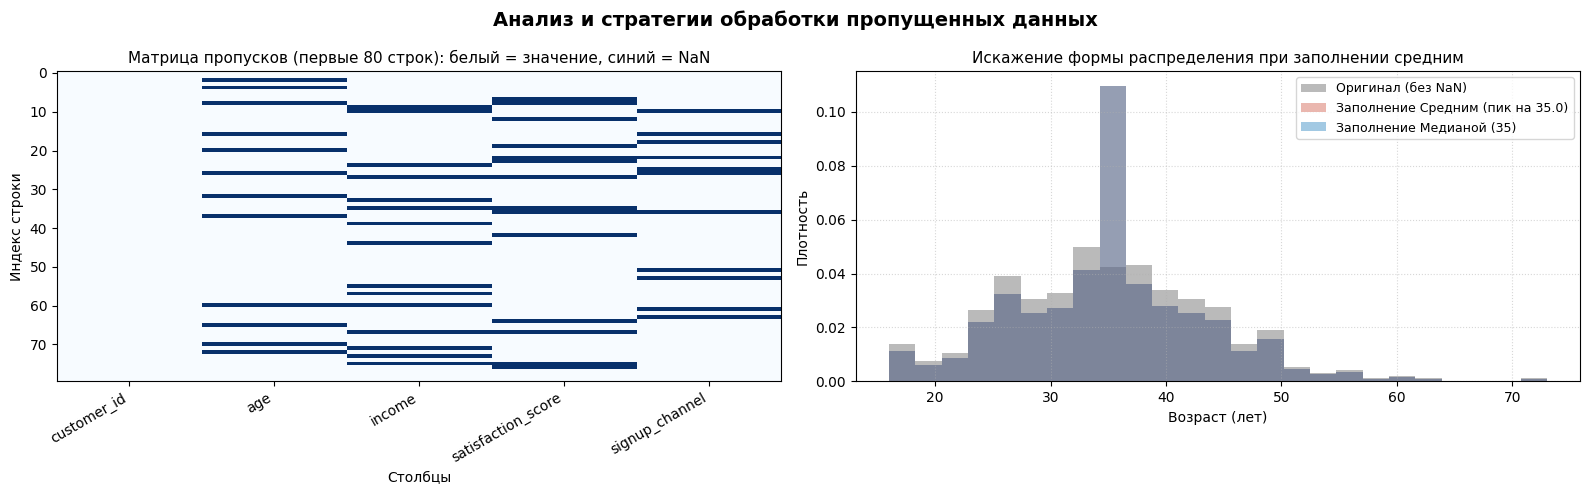

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Анализ и стратегии обработки пропущенных данных', fontsize=14, fontweight='bold')

# 1. Тепловая карта пропусков (Nullity Pattern)
ax1 = axes[0]
missing_matrix = dirty_data.isnull().values
im = ax1.imshow(missing_matrix[:80, :], cmap='Blues', aspect='auto', interpolation='nearest')
ax1.set_xticks(range(len(dirty_data.columns)))
ax1.set_xticklabels(dirty_data.columns, rotation=30, ha='right')
ax1.set_title('Матрица пропусков (первые 80 строк): белый = значение, синий = NaN', fontsize=11)
ax1.set_ylabel('Индекс строки')
ax1.set_xlabel('Столбцы')

# 2. Сравнение распределения до и после заполнения возраста
ax2 = axes[1]
original_ages = dirty_data['age'].dropna()
mean_imputed = dirty_data['age'].fillna(dirty_data['age'].mean())
median_imputed = dirty_data['age'].fillna(dirty_data['age'].median())

ax2.hist(original_ages, bins=25, alpha=0.5, color='#767676', label='Оригинал (без NaN)', density=True)
ax2.hist(mean_imputed, bins=25, alpha=0.4, color='#cc4b37', label=f'Заполнение Средним (пик на {original_ages.mean():.1f})', density=True)
ax2.hist(median_imputed, bins=25, alpha=0.4, color='#1779ba', label=f'Заполнение Медианой ({original_ages.median():.0f})', density=True)

ax2.set_title('Искажение формы распределения при заполнении средним', fontsize=11)
ax2.set_xlabel('Возраст (лет)')
ax2.set_ylabel('Плотность')
ax2.legend(fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Заполнение категориальных пропусков модой
Заполните пропуски в столбце `signup_channel` наиболее частым значением (модой) и убедитесь, что в столбце не осталось NaN.

In [4]:
### ВАШ КОД ЗДЕСЬ
mode_channel = dirty_data['signup_channel'].mode()[0]
clean_channel = dirty_data['signup_channel'].fillna(mode_channel)

null_count_after = clean_channel.isnull().sum()
print(f"Мода канала регистрации: {mode_channel}")
print(f"Осталось пропусков: {null_count_after}")

assert null_count_after == 0, "После заполнения модой пропусков быть не должно"
print("✅ Тест успешно пройден!")

Мода канала регистрации: Referral
Осталось пропусков: 0
✅ Тест успешно пройден!


### 💼 Чек-лист аналитика по пропускам:
1. **MCAR (Missing Completely at Random):** Пропуски случайны — можно удалять при <5%.
2. **MAR (Missing at Random):** Пропуск зависит от других полей — заполняем групповой медианой (например, зарплата по должностям).
3. **MNAR (Missing Not at Random):** Пропуск информативен сам по себе (например, клиенты с высоким доходом скрывают его) — создаем флаг `is_income_missing`.